In [1]:
# ÉTAPE 1 : Chargement, nettoyage, exploration, split train/test
# --- 1.1 Imports ---
import numpy as np                      # calcul numérique 
import pandas as pd                     # manipulation de tableaux de données (DataFrame)
import seaborn as sns                   # charge le dataset + graphiques statistiques
import matplotlib.pyplot as plt         # affichage des graphiques
from sklearn.model_selection import train_test_split  # séparation train/test
SEED = 42
np.random.seed(SEED)
# --- 1.2 Chargement des données ---
df = sns.load_dataset('mpg')            # charge le dataset "Auto MPG" dans un DataFrame
print("Dimensions brutes :", df.shape)  
print(df.head())                        # aperçu des 5 premières lignes
# --- 1.3 Inspection de la structure ---
df.info()                               # types de colonnes + nombre de valeurs non nulles
print(df.isna().sum())                  # nombre de valeurs manquantes par colonne 
print(df.describe())                    # stats (moyenne, écart-type, min, max) des variables numériques
# --- 1.4 Nettoyage ---
df = df.dropna()                        # supprime les lignes contenant au moins un NaN
df = df.drop(columns=['name'])          # 'name' = nom du modèle, texte quasi unique -> inutile
df = df.reset_index(drop=True)         
print("Dimensions après nettoyage :", df.shape)  

Dimensions brutes : (398, 9)
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-n

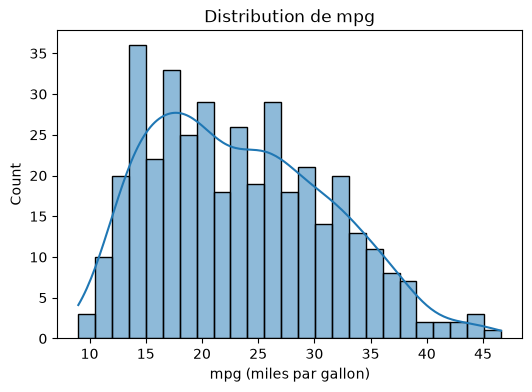

count    392.000000
mean      23.445918
std        7.805007
min        9.000000
25%       17.000000
50%       22.750000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64


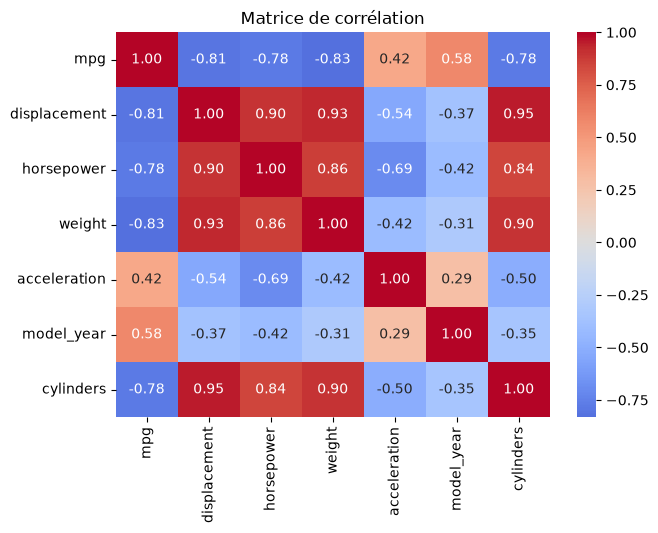

cylinders
3      4
4    199
5      3
6     83
8    103
Name: count, dtype: int64
origin
usa       245
japan      79
europe     68
Name: count, dtype: int64


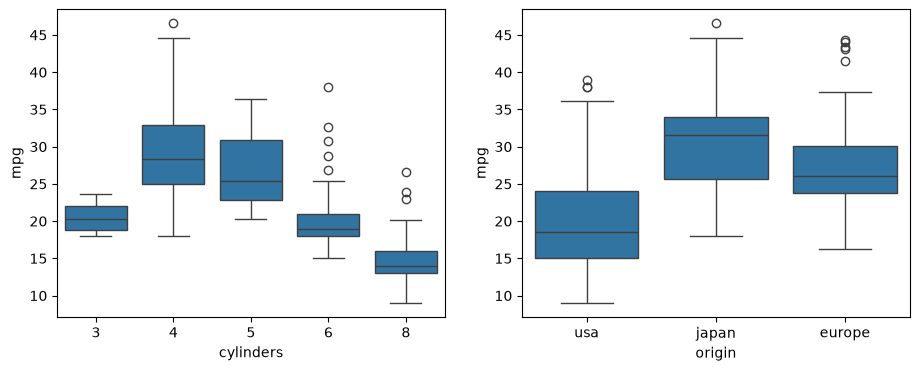

In [2]:
# --- 1.5 Exploration ---
# a) Distribution de la cible mpg : sa forme guidera le choix de la discrétisation
plt.figure(figsize=(6, 4))
sns.histplot(df['mpg'], bins=25, kde=True)
plt.title("Distribution de mpg")
plt.xlabel("mpg (miles par gallon)")
plt.show()
print(df['mpg'].describe())             # min, quartiles, max

# b) Matrice de corrélation des variables numériques
num_cols = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'cylinders']
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

# c) Variables catégorielles : combien de valeurs, quelle répartition ?
print(df['cylinders'].value_counts().sort_index())   
print(df['origin'].value_counts())                  
# d) Lien entre mpg et les variables catégorielles
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x='cylinders', y='mpg', ax=axes[0])
sns.boxplot(data=df, x='origin', y='mpg', ax=axes[1])
plt.show()


In [3]:
# --- 1.6 Séparation X / y ---
X = df.drop(columns=['mpg'])            # les 7 caractéristiques 
y = df['mpg']                           # la cible continue (on la transformera en classes plus tard)

# --- 1.7 Split train / test ---
# 80 % entraînement, 20 % test. random_state fixe le tirage aléatoire.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Train :", X_train.shape, " Test :", X_test.shape)   
# Vérification : les distributions de mpg doivent être similaires dans les deux ensembles
print(y_train.describe())
print(y_test.describe())

Train : (313, 7)  Test : (79, 7)
count    313.000000
mean      23.599361
std        7.956255
min        9.000000
25%       17.000000
50%       23.000000
75%       30.000000
max       46.600000
Name: mpg, dtype: float64
count    79.000000
mean     22.837975
std       7.189920
min      10.000000
25%      17.250000
50%      22.000000
75%      27.000000
max      44.000000
Name: mpg, dtype: float64


In [4]:
# ÉTAPE 2 : Pipeline de prétraitement

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#  2.1 Définition des groupes de variables 
num_features = ['cylinders', 'displacement', 'horsepower',
                'weight', 'acceleration', 'model_year']
# Variable catégorielle nominale
cat_features = ['origin']

# 2.2 Pipeline scikit-learn
# ColumnTransformer applique un traitement différent à chaque groupe de colonnes.
preprocessor = ColumnTransformer(
    transformers=[
        # StandardScaler : z = (x - moyenne) / écart-type, pour chaque colonne numérique
        ('num', StandardScaler(), num_features),
        # OneHotEncoder : origin -> 3 colonnes binaires (europe, japan, usa)
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
    ]
)
# fit_transform sur le TRAIN : apprend moyenne/écart-type/catégories, puis transforme
X_train_prep = preprocessor.fit_transform(X_train)
# transform seul sur le TEST : réutilise ce qui a été appris sur le train (pas de fuite)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Colonnes finales :", list(feature_names))
print("Shapes :", X_train_prep.shape, X_test_prep.shape) 

# 2.3 Vérification : les colonnes numériques sont centrées/réduites sur le train, et proches de 0/1 sur le test
print("Moyenne train (num) :", X_train_prep[:, :6].mean(axis=0).round(3))  # ~ 0
print("Écart-type train (num) :", X_train_prep[:, :6].std(axis=0).round(3))  # ~ 1
print("Moyenne test (num) :", X_test_prep[:, :6].mean(axis=0).round(3))

# 2.4 Version  (numpy) pour comprendre et valider 
mu = X_train[num_features].mean().values              # moyenne de chaque colonne (train)
sigma = X_train[num_features].std(ddof=0).values      # écart-type (ddof=0, comme sklearn)
Z_train = (X_train[num_features].values - mu) / sigma
Z_test = (X_test[num_features].values - mu) / sigma   # mêmes mu et sigma que le train

# One-hot manuel : une colonne par catégorie, 1 si la ligne appartient à la catégorie
categories = sorted(X_train['origin'].unique())       # ['europe', 'japan', 'usa']
def one_hot(col, cats):
    return np.column_stack([(col.values == c).astype(float) for c in cats])
O_train = one_hot(X_train['origin'], categories)
O_test = one_hot(X_test['origin'], categories)

X_train_manual = np.hstack([Z_train, O_train])
X_test_manual = np.hstack([Z_test, O_test])

# Les deux versions doivent être identiques
print("Manuel == sklearn (train) :", np.allclose(X_train_manual, X_train_prep))
print("Manuel == sklearn (test)  :", np.allclose(X_test_manual, X_test_prep))


# 2.5 Standardisation de la cible (pour la RÉGRESSION uniquement) 
y_mean = y_train.mean()
y_std = y_train.std(ddof=0)
y_train_s = ((y_train - y_mean) / y_std).values       # cible standardisée (train)
y_test_s = ((y_test - y_mean) / y_std).values         # mêmes y_mean, y_std que le train
# Pour revenir à l'unité d'origine (mpg) : y_pred_mpg = y_pred_s * y_std + y_mean
print(f"y_mean = {y_mean:.2f}, y_std = {y_std:.2f}")

#  2.6 Conversion en tableaux numpy simples 
# Pour l'implémentation from scratch, on travaille avec des np.ndarray
y_train_arr = y_train.values
y_test_arr = y_test.values

Colonnes finales : ['num__cylinders', 'num__displacement', 'num__horsepower', 'num__weight', 'num__acceleration', 'num__model_year', 'cat__origin_europe', 'cat__origin_japan', 'cat__origin_usa']
Shapes : (313, 9) (79, 9)
Moyenne train (num) : [-0.  0. -0.  0.  0. -0.]
Écart-type train (num) : [1. 1. 1. 1. 1. 1.]
Moyenne test (num) : [-0.031 -0.053 -0.016 -0.05  -0.005 -0.312]
Manuel == sklearn (train) : True
Manuel == sklearn (test)  : True
y_mean = 23.60, y_std = 7.94


In [7]:

# ÉTAPE 3 : Classification (SVC) - discrétisation, from scratch, sklearn
# X_train_prep, X_test_prep (313x9, 79x9),
# y_train, y_test (mpg en valeurs continues), SEED
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 3.1 DISCRÉTISATION DE LA CIBLE
class_names = ['conso élevée (mpg bas)', 'conso moyenne', 'conso faible (mpg haut)']
# Stratégie A : tertiles, calculés sur le TRAIN seulement
q1, q2 = np.quantile(y_train, [1/3, 2/3])
# np.digitize(y, [q1, q2]) renvoie 0 si y < q1, 1 si q1 <= y < q2, 2 si y >= q2
yA_train = np.digitize(y_train, [q1, q2])
yA_test = np.digitize(y_test, [q1, q2])        # mêmes seuils que le train

# Stratégie B : seuils fixes (interprétables)
yB_train = np.digitize(y_train, [20, 30])
yB_test = np.digitize(y_test, [20, 30])

print(f"Seuils tertiles : {q1:.1f} et {q2:.1f}")
for name, ytr, yte in [('A (tertiles)', yA_train, yA_test),
                       ('B (seuils 20/30)', yB_train, yB_test)]:
    print(f"\nStratégie {name}")
    print(" train :", np.bincount(ytr), (np.bincount(ytr) / len(ytr)).round(2))
    print(" test  :", np.bincount(yte), (np.bincount(yte) / len(yte)).round(2))
# Constat attendu : A est équilibrée, B est déséquilibrée (classe 2 minoritaire).
# Choix pour la suite : stratégie A (équilibrée), plus propre pour comparer les modèles.
# La stratégie B sert à discuter l'impact du déséquilibre .
ytr_cls, yte_cls = yA_train, yA_test


# 3.2 NOYAUX (utilisés par le SVM dual from scratch)
def kernel_matrix(A, B, kind='rbf', gamma=0.1, degree=3, coef0=1.0):
    """Matrice de Gram K[i,j] = k(A[i], B[j])."""
    if kind == 'linear':
        return A @ B.T                                   # k(x,z) = <x,z>
    if kind == 'rbf':
        # ||a-b||^2 = ||a||^2 + ||b||^2 - 2<a,b>  (calcul vectorisé, sans boucle)
        sq = (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T
        return np.exp(-gamma * np.maximum(sq, 0))        # k(x,z) = exp(-gamma ||x-z||^2)
    if kind == 'poly':
        return (gamma * (A @ B.T) + coef0) ** degree     # k(x,z) = (gamma<x,z> + coef0)^degree
    raise ValueError(kind)

# 3.3 SVM LINÉAIRE BINAIRE (primal, sous-gradient)
# Objectif sklearn : 0.5*||w||^2 + C * somme_i max(0, 1 - y_i (w.x_i + b))
# On minimise l'objectif divisé par (C*n) : lam/2 ||w||^2 + moyenne(hinge), lam = 1/(C n)
# (même minimiseur, mais pas de plus stable numériquement)
# ------------------------------------------------------------
class LinearSVMScratch:
    def __init__(self, C=1.0, n_iter=3000, lr0=0.1):
        self.C, self.n_iter, self.lr0 = C, n_iter, lr0

    def fit(self, X, y):                       # y dans {-1, +1}
        n, d = X.shape
        lam = 1.0 / (self.C * n)
        w, b = np.zeros(d), 0.0
        self.history = []
        for t in range(1, self.n_iter + 1):
            margin = y * (X @ w + b)           # marge fonctionnelle de chaque point
            viol = margin < 1                  # points qui violent la marge (hinge > 0)
            # sous-gradient : lam*w - (1/n) * somme_{violateurs} y_i x_i
            grad_w = lam * w - (X[viol].T @ y[viol]) / n
            grad_b = -y[viol].sum() / n
            lr = self.lr0 / np.sqrt(t)         # pas décroissant (nécessaire en sous-gradient)
            w -= lr * grad_w
            b -= lr * grad_b
            if t % 50 == 0:                    # suivi de l'objectif (forme sklearn)
                hinge = np.maximum(0, 1 - y * (X @ w + b)).sum()
                self.history.append(0.5 * w @ w + self.C * hinge)
        self.w, self.b = w, b
        return self

    def decision_function(self, X):
        return X @ self.w + self.b

# ------------------------------------------------------------
# 3.4 SVM À NOYAU BINAIRE (dual, SMO simplifié de Platt)
# Dual : max_alpha sum(alpha) - 0.5 sum_ij alpha_i alpha_j y_i y_j K_ij
#        sous 0 <= alpha_i <= C et sum alpha_i y_i = 0
# SMO optimise 2 multiplicateurs à la fois (la contrainte d'égalité l'impose)
# ------------------------------------------------------------
class KernelSVMScratch:
    def __init__(self, C=1.0, kernel='rbf', gamma=0.1, degree=3, coef0=1.0,
                 tol=1e-3, max_passes=5, max_iter=200, seed=0):
        self.C, self.kernel, self.gamma = C, kernel, gamma
        self.degree, self.coef0 = degree, coef0
        self.tol, self.max_passes, self.max_iter = tol, max_passes, max_iter
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):                       # y dans {-1, +1}
        n = len(y)
        K = kernel_matrix(X, X, self.kernel, self.gamma, self.degree, self.coef0)
        alpha, b, C = np.zeros(n), 0.0, self.C
        passes, it = 0, 0
        while passes < self.max_passes and it < self.max_iter:
            changed = 0
            for i in range(n):
                Ei = (alpha * y) @ K[:, i] + b - y[i]        # erreur f(x_i) - y_i
                # i viole-t-il les conditions KKT (à tol près) ?
                if (y[i] * Ei < -self.tol and alpha[i] < C) or \
                   (y[i] * Ei > self.tol and alpha[i] > 0):
                    j = self.rng.integers(n - 1)             # j aléatoire, j != i
                    j = j + 1 if j >= i else j
                    Ej = (alpha * y) @ K[:, j] + b - y[j]
                    ai_old, aj_old = alpha[i], alpha[j]
                    # bornes L, H pour alpha_j (garantissent 0<=alpha<=C et sum alpha y = 0)
                    if y[i] != y[j]:
                        L, H = max(0, aj_old - ai_old), min(C, C + aj_old - ai_old)
                    else:
                        L, H = max(0, ai_old + aj_old - C), min(C, ai_old + aj_old)
                    if L == H:
                        continue
                    eta = 2 * K[i, j] - K[i, i] - K[j, j]    # dérivée seconde (<= 0)
                    if eta >= 0:
                        continue
                    aj = np.clip(aj_old - y[j] * (Ei - Ej) / eta, L, H)
                    if abs(aj - aj_old) < 1e-5:
                        continue
                    ai = ai_old + y[i] * y[j] * (aj_old - aj)  # maintient sum alpha y = 0
                    # mise à jour du biais b pour respecter KKT
                    b1 = b - Ei - y[i]*(ai-ai_old)*K[i, i] - y[j]*(aj-aj_old)*K[i, j]
                    b2 = b - Ej - y[i]*(ai-ai_old)*K[i, j] - y[j]*(aj-aj_old)*K[j, j]
                    b = b1 if 0 < ai < C else (b2 if 0 < aj < C else (b1 + b2) / 2)
                    alpha[i], alpha[j] = ai, aj
                    changed += 1
            passes = passes + 1 if changed == 0 else 0       # convergé après plusieurs passes sans changement
            it += 1
        sv = alpha > 1e-6                                    # vecteurs de support : alpha > 0
        self.support_ = np.where(sv)[0]
        self.X_sv, self.coef, self.b = X[sv], (alpha * y)[sv], b
        return self

    def decision_function(self, X):
        # f(x) = sum_i alpha_i y_i k(x_i, x) + b  (uniquement sur les vecteurs de support)
        K = kernel_matrix(X, self.X_sv, self.kernel, self.gamma, self.degree, self.coef0)
        return K @ self.coef + self.b


# ------------------------------------------------------------
# 3.5 MULTICLASSE : UN-CONTRE-TOUS (OvR)
# 1 classifieur binaire par classe (classe c = +1, autres = -1).
# Prédiction : la classe dont le score de décision est le plus grand.
# ------------------------------------------------------------
class OneVsRestScratch:
    def __init__(self, make_model):
        self.make_model = make_model                 # fonction qui crée un modèle binaire neuf

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = []
        for c in self.classes_:
            yb = np.where(y == c, 1.0, -1.0)
            self.models_.append(self.make_model().fit(X, yb))
        return self

    def decision_function(self, X):
        return np.column_stack([m.decision_function(X) for m in self.models_])

    def predict(self, X):
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

    def n_support(self):                             # nb de points distincts utilisés comme SV
        if not hasattr(self.models_[0], 'support_'):
            return None                              # modèle primal : pas de SV explicites
        return len(np.unique(np.concatenate([m.support_ for m in self.models_])))

# ------------------------------------------------------------
# 3.6 RÉGLAGE DES HYPERPARAMÈTRES (validation croisée sur le train, via sklearn)
# ------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(
    SVC(kernel='rbf'),
    {'C': [0.1, 1, 10, 100], 'gamma': [0.003, 0.01, 0.03, 0.1, 0.3]},
    cv=cv, scoring='f1_macro')
grid.fit(X_train_prep, ytr_cls)
C_rbf, gamma_rbf = grid.best_params_['C'], grid.best_params_['gamma']
print("Meilleurs paramètres RBF :", grid.best_params_, " F1 CV :", round(grid.best_score_, 3))

C_lin = 1.0                                           # à régler de la même façon si tu veux
# gamma='scale' de sklearn = 1 / (n_features * variance(X)) : on le recalcule pour le poly
gamma_scale = 1.0 / (X_train_prep.shape[1] * X_train_prep.var())

Seuils tertiles : 18.5 et 27.0

Stratégie A (tertiles)
 train : [104  99 110] [0.33 0.32 0.35]
 test  : [23 35 21] [0.29 0.44 0.27]

Stratégie B (seuils 20/30)
 train : [122 111  80] [0.39 0.35 0.26]
 test  : [29 40 10] [0.37 0.51 0.13]
Meilleurs paramètres RBF : {'C': 1, 'gamma': 0.1}  F1 CV : 0.846


                       modèle  accuracy  F1 macro  nb SV
  Linéaire - scratch (primal)     0.582     0.572    NaN
 Linéaire - LinearSVC (hinge)     0.633     0.629    NaN
     RBF - scratch (SMO, OvR)     0.797     0.803  184.0
      RBF - sklearn SVC (OvR)     0.797     0.803  180.0
RBF - sklearn SVC (OvO natif)     0.772     0.778  164.0
Poly d=3 - scratch (SMO, OvR)     0.797     0.802  151.0
 Poly d=3 - sklearn SVC (OvR)     0.797     0.801  145.0

Accord scratch/sklearn :
 linéaire : 0.949
 RBF      : 1.0
 poly     : 0.987

Matrice de confusion RBF scratch (lignes = vrai, colonnes = prédit) :
[[20  3  0]
 [ 4 25  6]
 [ 0  3 18]]


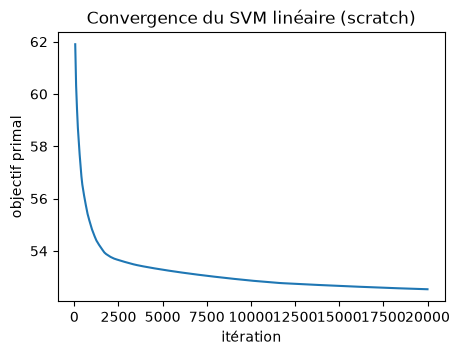


--- Diagnostic linéaire ---
Objectif scratch (3 classifieurs) : [np.float64(52.54), np.float64(198.07), np.float64(60.93)]
classe 0 : objectif LinearSVC = 52.34
classe 1 : objectif LinearSVC = 198.09
classe 2 : objectif LinearSVC = 61.13
Accord linéaire : 0.949

Matrice de confusion linéaire scratch :
[[20  2  1]
 [11  8 16]
 [ 0  3 18]]

Matrice de confusion LinearSVC :
[[21  1  1]
 [ 9 11 15]
 [ 0  3 18]]

 discrétisation class_weight  accuracy  F1 macro
    A tertiles          NaN     0.772     0.778
    A tertiles     balanced     0.797     0.803
B seuils 20/30          NaN     0.810     0.799
B seuils 20/30     balanced     0.772     0.764


In [10]:
# ------------------------------------------------------------
# 3.7 ENTRAÎNEMENT ET COMPARAISON (version complète corrigée)
# ------------------------------------------------------------
def evaluate(name, y_true, y_pred, n_sv=None):
    return {'modèle': name,
            'accuracy': accuracy_score(y_true, y_pred),
            'F1 macro': f1_score(y_true, y_pred, average='macro'),
            'nb SV': n_sv}

results, preds = [], {}

# --- (a) Linéaire : scratch primal vs sklearn ---
lin_s = OneVsRestScratch(lambda: LinearSVMScratch(C=C_lin)).fit(X_train_prep, ytr_cls)
preds['lin_scratch'] = lin_s.predict(X_test_prep)
results.append(evaluate('Linéaire - scratch (primal)', yte_cls, preds['lin_scratch']))

# LinearSVC : OvR par défaut ; loss='hinge' pour avoir la MÊME perte que ton code
lin_sk = LinearSVC(C=C_lin, loss='hinge', max_iter=50000, random_state=SEED).fit(X_train_prep, ytr_cls)
preds['lin_sk'] = lin_sk.predict(X_test_prep)
results.append(evaluate('Linéaire - LinearSVC (hinge)', yte_cls, preds['lin_sk']))

# --- (b) RBF : scratch (SMO) vs sklearn ---
rbf_s = OneVsRestScratch(lambda: KernelSVMScratch(C=C_rbf, kernel='rbf', gamma=gamma_rbf)).fit(X_train_prep, ytr_cls)
preds['rbf_scratch'] = rbf_s.predict(X_test_prep)
results.append(evaluate('RBF - scratch (SMO, OvR)', yte_cls, preds['rbf_scratch'], rbf_s.n_support()))

rbf_ovr = OneVsRestClassifier(SVC(kernel='rbf', C=C_rbf, gamma=gamma_rbf)).fit(X_train_prep, ytr_cls)
preds['rbf_ovr'] = rbf_ovr.predict(X_test_prep)
n_sv_ovr = len(np.unique(np.concatenate([e.support_ for e in rbf_ovr.estimators_])))
results.append(evaluate('RBF - sklearn SVC (OvR)', yte_cls, preds['rbf_ovr'], n_sv_ovr))

rbf_ovo = SVC(kernel='rbf', C=C_rbf, gamma=gamma_rbf).fit(X_train_prep, ytr_cls)   # OvO natif
preds['rbf_ovo'] = rbf_ovo.predict(X_test_prep)
results.append(evaluate('RBF - sklearn SVC (OvO natif)', yte_cls, preds['rbf_ovo'], len(rbf_ovo.support_)))

# --- (c) Polynomial (degré 3) : scratch vs sklearn ---
poly_s = OneVsRestScratch(lambda: KernelSVMScratch(C=1.0, kernel='poly', gamma=gamma_scale,
                                                   degree=3, coef0=1.0)).fit(X_train_prep, ytr_cls)
preds['poly_scratch'] = poly_s.predict(X_test_prep)
results.append(evaluate('Poly d=3 - scratch (SMO, OvR)', yte_cls, preds['poly_scratch'], poly_s.n_support()))

poly_ovr = OneVsRestClassifier(SVC(kernel='poly', degree=3, coef0=1.0, gamma=gamma_scale, C=1.0)
                               ).fit(X_train_prep, ytr_cls)
preds['poly_ovr'] = poly_ovr.predict(X_test_prep)
n_sv_poly = len(np.unique(np.concatenate([e.support_ for e in poly_ovr.estimators_])))
results.append(evaluate('Poly d=3 - sklearn SVC (OvR)', yte_cls, preds['poly_ovr'], n_sv_poly))

# --- Tableau récapitulatif ---
print(pd.DataFrame(results).round(3).to_string(index=False))

# --- Accord scratch / sklearn (part de prédictions identiques) ---
print("\nAccord scratch/sklearn :")
print(" linéaire :", np.mean(preds['lin_scratch'] == preds['lin_sk']).round(3))
print(" RBF      :", np.mean(preds['rbf_scratch'] == preds['rbf_ovr']).round(3))
print(" poly     :", np.mean(preds['poly_scratch'] == preds['poly_ovr']).round(3))

# --- Matrice de confusion RBF scratch ---
print("\nMatrice de confusion RBF scratch (lignes = vrai, colonnes = prédit) :")
print(confusion_matrix(yte_cls, preds['rbf_scratch']))

# --- Courbe de convergence du SVM linéaire (première classe) ---
plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, len(lin_s.models_[0].history) + 1) * 50, lin_s.models_[0].history)
plt.xlabel("itération"); plt.ylabel("objectif primal"); plt.title("Convergence du SVM linéaire (scratch)")
plt.show()

# --- DIAGNOSTIC du SVC linéaire : scratch vs LinearSVC ---
print("\n--- Diagnostic linéaire ---")
print("Objectif scratch (3 classifieurs) :", [round(m.objective_, 2) for m in lin_s.models_])
for c in range(3):
    yb = np.where(ytr_cls == c, 1.0, -1.0)
    sk = LinearSVC(C=C_lin, loss='hinge', max_iter=50000, random_state=SEED).fit(X_train_prep, yb)
    obj = 0.5 * (sk.coef_ @ sk.coef_.T).item() \
          + C_lin * np.maximum(0, 1 - yb * sk.decision_function(X_train_prep)).sum()
    print(f"classe {c} : objectif LinearSVC = {obj:.2f}")
print("Accord linéaire :", np.mean(preds['lin_scratch'] == preds['lin_sk']).round(3))
print("\nMatrice de confusion linéaire scratch :")
print(confusion_matrix(yte_cls, preds['lin_scratch']))
print("\nMatrice de confusion LinearSVC :")
print(confusion_matrix(yte_cls, preds['lin_sk']))
 


# ------------------------------------------------------------
# 3.8 IMPACT DE LA STRATÉGIE DE DISCRÉTISATION (pour la discussion)

rows = []
for name, ytr, yte in [('A tertiles', yA_train, yA_test), ('B seuils 20/30', yB_train, yB_test)]:
    for cw in [None, 'balanced']:                    # 'balanced' pondère les classes rares
        m = SVC(kernel='rbf', C=C_rbf, gamma=gamma_rbf, class_weight=cw).fit(X_train_prep, ytr)
        p = m.predict(X_test_prep)
        rows.append({'discrétisation': name, 'class_weight': cw,
                     'accuracy': accuracy_score(yte, p),
                     'F1 macro': f1_score(yte, p, average='macro')})
print("\n", pd.DataFrame(rows).round(3).to_string(index=False))

Meilleurs paramètres SVR linéaire : {'C': 0.1, 'epsilon': 0.3}  RMSE CV = 3.37 mpg

--- Comparaison à epsilon = 0.1 (soit 0.79 mpg), C = 0.1 ---
                    modèle  RMSE test (mpg)  R² test  nb SV (train)
   Scratch (sous-gradient)            3.368    0.778            256
sklearn SVR(kernel=linear)            3.368    0.778            245
         sklearn LinearSVR            3.373    0.777            258

Coefficients (cible standardisée) :
           variable  scratch  SVR linear  LinearSVR
    num__cylinders   -0.077      -0.077     -0.078
 num__displacement   -0.050      -0.050     -0.048
   num__horsepower   -0.096      -0.096     -0.097
       num__weight   -0.425      -0.425     -0.423
 num__acceleration   -0.064      -0.064     -0.065
   num__model_year    0.286       0.286      0.286
cat__origin_europe    0.018       0.014      0.014
 cat__origin_japan    0.216       0.212      0.215
   cat__origin_usa   -0.222      -0.227     -0.228
Écart max |w_scratch - w_SVR| : 0.0

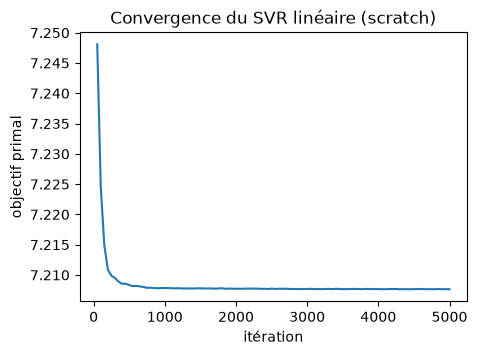


  eps  eps (mpg)  nb SV sklearn  nb SV scratch  % SV (sklearn)  RMSE train  RMSE test  RMSE test scratch  ||w||
0.00      0.000            313            313         100.000       3.433      3.360              3.362  0.622
0.05      0.397            280            294          89.457       3.435      3.346              3.349  0.624
0.10      0.794            245            256          78.275       3.435      3.368              3.368  0.617
0.20      1.589            188            196          60.064       3.364      3.278              3.282  0.654
0.30      2.383            138            146          44.089       3.331      3.229              3.229  0.713
0.50      3.972             64             71          20.447       3.343      3.265              3.265  0.707
0.75      5.958             32             34          10.224       3.458      3.486              3.483  0.643
1.00      7.944             14             15           4.473       3.751      3.892              3.885  0.586

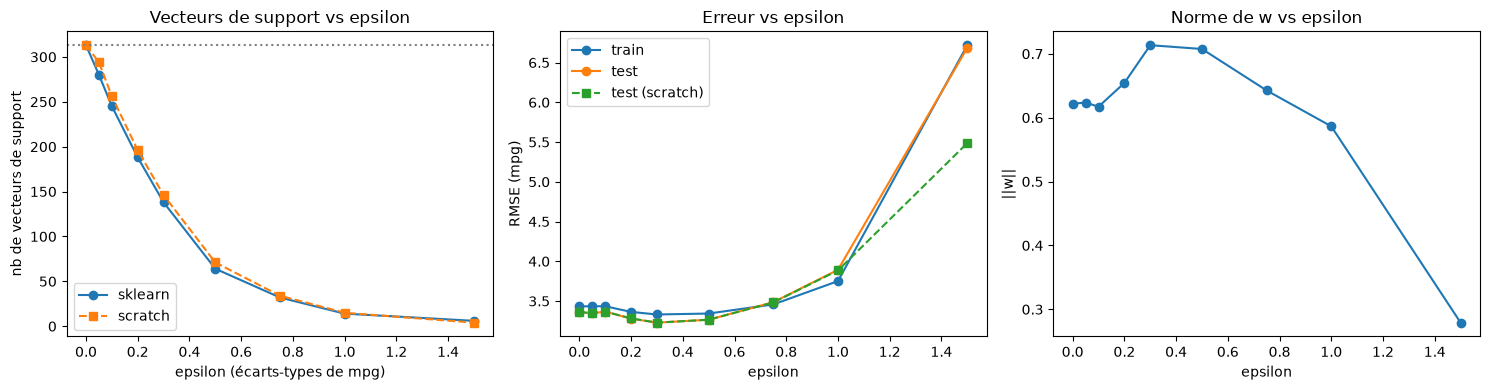


--- Robustesse au bruit (test évalué sur la cible PROPRE) ---
                    modèle  nb SV  RMSE test (mpg)
         MCO, cible propre    NaN            3.256
        MCO, cible bruitée    NaN            3.662
  SVR eps=0, cible bruitée  313.0            3.305
SVR eps=0.1, cible bruitée  267.0            3.370
SVR eps=0.3, cible bruitée  159.0            3.337
SVR eps=0.5, cible bruitée  110.0            3.392
SVR eps=1.0, cible bruitée   38.0            3.844


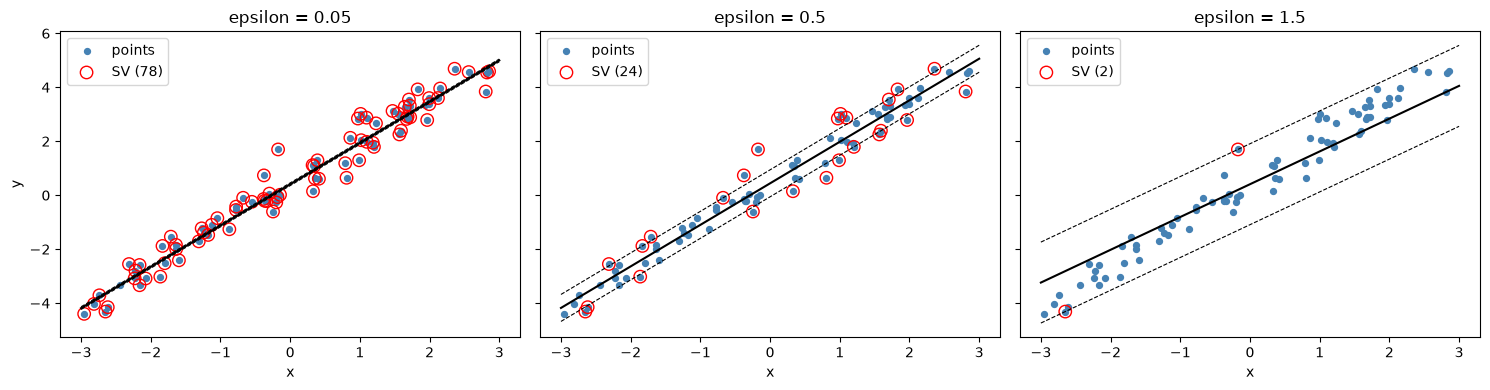

In [6]:
# ÉTAPE 4 : Régression (SVR linéaire, perte ε-insensible)
#  X_train_prep, X_test_prep, y_train_s, y_test_s,
# y_mean, y_std, feature_names, SEED
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR, LinearSVR
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold

Xtr, Xte = X_train_prep, X_test_prep
ytr_s, yte_s = y_train_s, y_test_s          # cibles standardisées (étape 2.5)


# 4.1 OUTILS : métriques (ramenées en mpg) et comptage des vecteurs de support
# ------------------------------------------------------------
def rmse_mpg(y_s, p_s):
    # RMSE sur la cible standardisée, multiplié par y_std -> erreur en mpg
    return np.sqrt(np.mean((y_s - p_s) ** 2)) * y_std

def r2_score_(y_s, p_s):
    # R² = 1 - SS_res / SS_tot (invariant par standardisation)
    return 1 - np.sum((y_s - p_s) ** 2) / np.sum((y_s - y_s.mean()) ** 2)

def count_sv(y, pred, eps, tol=0.02):
    # Un point est vecteur de support s'il est SUR ou HORS du tube : |r| >= eps.
    # tol : tolérance numérique (la descente de gradient n'atterrit jamais exactement sur le bord du tube).
    return int(np.sum(np.abs(y - pred) >= eps - tol))

# ------------------------------------------------------------
# 4.2 SVR LINÉAIRE FROM SCRATCH (primal, sous-gradient)
# Objectif sklearn : 0.5*||w||^2 + C * somme_i max(0, |y_i - (w.x_i + b)| - eps)
# On minimise l'objectif divisé par (C*n) : lam/2 ||w||^2 + moyenne(perte), lam = 1/(C n)
# ------------------------------------------------------------
class LinearSVRScratch:
    def __init__(self, C=1.0, epsilon=0.1, n_iter=5000, lr0=0.5, sv_tol=0.02):
        self.C, self.epsilon = C, epsilon
        self.n_iter, self.lr0, self.sv_tol = n_iter, lr0, sv_tol

    def fit(self, X, y):
        n, d = X.shape
        lam = 1.0 / (self.C * n)
        w, b = np.zeros(d), 0.0
        best_obj, best = np.inf, (w.copy(), b)
        self.history = []
        for t in range(1, self.n_iter + 1):
            r = y - (X @ w + b)                              # résidus
            excess = np.maximum(0, np.abs(r) - self.epsilon) # perte eps-insensible par point
            obj = 0.5 * w @ w + self.C * excess.sum()        # objectif forme sklearn
            if obj < best_obj:                               # on garde la meilleure solution vue
                best_obj, best = obj, (w.copy(), b)          # (le sous-gradient oscille un peu)
            if t % 50 == 0:
                self.history.append(obj)
            # Sous-gradient : seuls les points HORS du tube (|r| > eps) contribuent.
            # d L_eps / d w = -sign(r) * x   pour |r| > eps, 0 sinon.
            s = np.sign(r) * (excess > 0)
            grad_w = lam * w - (X.T @ s) / n
            grad_b = -s.sum() / n
            lr = self.lr0 / np.sqrt(t)                       # pas décroissant
            w = w - lr * grad_w
            b = b - lr * grad_b
        self.w, self.b = best
        self.objective_ = best_obj
        # vecteurs de support = points sur ou hors du tube
        r = y - self.predict(X)
        self.support_ = np.where(np.abs(r) >= self.epsilon - self.sv_tol)[0]
        return self

    def predict(self, X):
        return X @ self.w + self.b

# ------------------------------------------------------------
# 4.3 RÉGLAGE DE C ET ε PAR VALIDATION CROISÉE (sklearn, SVR linéaire)
# ------------------------------------------------------------
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(
    SVR(kernel='linear'),
    {'C': [0.01, 0.1, 1, 10], 'epsilon': [0.05, 0.1, 0.2, 0.3, 0.5]},
    cv=cv, scoring='neg_root_mean_squared_error')
grid.fit(Xtr, ytr_s)
C_svr = grid.best_params_['C']
print("Meilleurs paramètres SVR linéaire :", grid.best_params_,
      f" RMSE CV = {-grid.best_score_ * y_std:.2f} mpg")

# ------------------------------------------------------------
# 4.4 COMPARAISON scratch vs sklearn pour un ε de référence
# ------------------------------------------------------------
eps_ref = 0.1

svr_sc = LinearSVRScratch(C=C_svr, epsilon=eps_ref).fit(Xtr, ytr_s)
svr_sk = SVR(kernel='linear', C=C_svr, epsilon=eps_ref).fit(Xtr, ytr_s)
# LinearSVR : perte epsilon-insensible L1, solveur primal/dual de liblinear.
# intercept_scaling grand : liblinear régularise l'intercept par défaut, ce qui le biaise ;
# un facteur 10 rend cette pénalisation négligeable.
lsvr = LinearSVR(C=C_svr, epsilon=eps_ref, loss='epsilon_insensitive', dual=True,
                 intercept_scaling=10.0, max_iter=100000, random_state=SEED).fit(Xtr, ytr_s)

rows = []
for name, model, n_sv in [
        ('Scratch (sous-gradient)', svr_sc, len(svr_sc.support_)),
        ('sklearn SVR(kernel=linear)', svr_sk, len(svr_sk.support_)),
        ('sklearn LinearSVR', lsvr, count_sv(ytr_s, lsvr.predict(Xtr), eps_ref))]:
    p_te = model.predict(Xte)
    rows.append({'modèle': name,
                 'RMSE test (mpg)': rmse_mpg(yte_s, p_te),
                 'R² test': r2_score_(yte_s, p_te),
                 'nb SV (train)': n_sv})
print(f"\n--- Comparaison à epsilon = {eps_ref} (soit {eps_ref * y_std:.2f} mpg), C = {C_svr} ---")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Comparaison des coefficients appris (doivent être proches)
coef_df = pd.DataFrame({
    'variable': list(feature_names),
    'scratch': svr_sc.w,
    'SVR linear': svr_sk.coef_.ravel(),
    'LinearSVR': lsvr.coef_.ravel()}).round(3)
print("\nCoefficients (cible standardisée) :\n", coef_df.to_string(index=False))
print("Écart max |w_scratch - w_SVR| :", np.abs(svr_sc.w - svr_sk.coef_.ravel()).max().round(4))

# Convergence de l'implémentation scratch
plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, len(svr_sc.history) + 1) * 50, svr_sc.history)
plt.xlabel("itération"); plt.ylabel("objectif primal")
plt.title("Convergence du SVR linéaire (scratch)")
plt.show()

# ------------------------------------------------------------
# 4.5 INFLUENCE DE ε : nombre de SV et erreur
# ------------------------------------------------------------
eps_grid = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5]
sweep = []
for eps in eps_grid:
    sk = SVR(kernel='linear', C=C_svr, epsilon=eps).fit(Xtr, ytr_s)
    sc = LinearSVRScratch(C=C_svr, epsilon=eps).fit(Xtr, ytr_s)
    sweep.append({
        'eps': eps, 'eps (mpg)': eps * y_std,
        'nb SV sklearn': len(sk.support_),
        'nb SV scratch': len(sc.support_),
        '% SV (sklearn)': 100 * len(sk.support_) / len(ytr_s),
        'RMSE train': rmse_mpg(ytr_s, sk.predict(Xtr)),
        'RMSE test': rmse_mpg(yte_s, sk.predict(Xte)),
        'RMSE test scratch': rmse_mpg(yte_s, sc.predict(Xte)),
        '||w||': np.linalg.norm(sk.coef_)})
sweep_df = pd.DataFrame(sweep)
print("\n", sweep_df.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(sweep_df['eps'], sweep_df['nb SV sklearn'], 'o-', label='sklearn')
ax[0].plot(sweep_df['eps'], sweep_df['nb SV scratch'], 's--', label='scratch')
ax[0].axhline(len(ytr_s), color='gray', ls=':'); ax[0].legend()
ax[0].set_xlabel("epsilon (écarts-types de mpg)"); ax[0].set_ylabel("nb de vecteurs de support")
ax[0].set_title("Vecteurs de support vs epsilon")
ax[1].plot(sweep_df['eps'], sweep_df['RMSE train'], 'o-', label='train')
ax[1].plot(sweep_df['eps'], sweep_df['RMSE test'], 'o-', label='test')
ax[1].plot(sweep_df['eps'], sweep_df['RMSE test scratch'], 's--', label='test (scratch)')
ax[1].legend(); ax[1].set_xlabel("epsilon"); ax[1].set_ylabel("RMSE (mpg)")
ax[1].set_title("Erreur vs epsilon")
ax[2].plot(sweep_df['eps'], sweep_df['||w||'], 'o-')
ax[2].set_xlabel("epsilon"); ax[2].set_ylabel("||w||")
ax[2].set_title("Norme de w vs epsilon")
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 4.6 CAPACITÉ À IGNORER LE BRUIT : cible d'entraînement contaminée, test propre
# ------------------------------------------------------------
rng = np.random.default_rng(SEED)
y_noisy = ytr_s + rng.normal(0, 0.3, size=len(ytr_s))              # bruit gaussien (sigma = 0.3)
idx = rng.choice(len(ytr_s), size=int(0.05 * len(ytr_s)), replace=False)
y_noisy[idx] += rng.choice([-3.0, 3.0], size=len(idx))              # 5 % d'outliers (+/- 3 sigma)

rows = []
ols_clean = LinearRegression().fit(Xtr, ytr_s)
rows.append({'modèle': 'MCO, cible propre', 'nb SV': None,
             'RMSE test (mpg)': rmse_mpg(yte_s, ols_clean.predict(Xte))})
ols_noisy = LinearRegression().fit(Xtr, y_noisy)
rows.append({'modèle': 'MCO, cible bruitée', 'nb SV': None,
             'RMSE test (mpg)': rmse_mpg(yte_s, ols_noisy.predict(Xte))})
for eps in [0, 0.1, 0.3, 0.5, 1.0]:
    m = SVR(kernel='linear', C=C_svr, epsilon=eps).fit(Xtr, y_noisy)
    rows.append({'modèle': f'SVR eps={eps}, cible bruitée', 'nb SV': len(m.support_),
                 'RMSE test (mpg)': rmse_mpg(yte_s, m.predict(Xte))})
print("\n--- Robustesse au bruit (test évalué sur la cible PROPRE) ---")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ------------------------------------------------------------
# 4.7 ILLUSTRATION 1D : le tube epsilon et les vecteurs de support
# ------------------------------------------------------------
rng = np.random.default_rng(SEED)
x1 = rng.uniform(-3, 3, 80)
y1 = 1.5 * x1 + 0.5 + rng.normal(0, 0.5, 80)        # droite + bruit (sigma = 0.5)
X1 = x1.reshape(-1, 1)
xl = np.linspace(-3, 3, 100)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, eps in zip(axes, [0.05, 0.5, 1.5]):
    m = LinearSVRScratch(C=10, epsilon=eps, n_iter=8000).fit(X1, y1)
    line = m.w[0] * xl + m.b
    a.scatter(x1, y1, s=18, color='steelblue', label='points')
    a.scatter(x1[m.support_], y1[m.support_], s=80, facecolors='none',
              edgecolors='red', label=f'SV ({len(m.support_)})')
    a.plot(xl, line, 'k-')
    a.plot(xl, line + eps, 'k--', lw=0.8); a.plot(xl, line - eps, 'k--', lw=0.8)
    a.set_title(f"epsilon = {eps}"); a.set_xlabel("x"); a.legend()
axes[0].set_ylabel("y")
plt.tight_layout(); plt.show()